#  DSA5102 Final Project: Tetuan-City-Power-Consumption
- Group members： FengZhengqi, GeYuzi, WangKe, ZengZijie, ZhouSishuo.
  
  (The names are arranged alphabetically.)

## 1. Introduction and Problem Definition
**Central question: how do weather and time affect electricity demand in
the three distribution zones of Tetouan, do the zones share common or
different daily consumption patterns, and do these patterns affect how
reliable demand predictions are?**

### 1.1 Executive Summary
**Research question.** We study what drives electricity demand in
Tetouan, Morocco, in three ways: how well demand can be predicted from
weather and time, how much daily load curves can be compressed into a
few patterns, and whether days fall into typical "load regimes".

**Data.** The UCI *Power Consumption of Tetouan City* dataset:
52,416 ten-minute records for 2017 (364 complete days), with temperature,
humidity, wind speed, two solar-radiation measures and the demand of
three zones. Ten-minute records are the sample unit for prediction;
days (72-dimensional curves: 3 zones × 24 hours) are the unit for the
unsupervised tasks.

**Three tasks.**
1. *Task 1, supervised regression:* predict each zone's demand at every ten-minute point with Ridge regression, Random Forest and Gradient Boosting.
2. *Task 2, dimensionality reduction:* summarise daily load curves with PCA and Kernel PCA.
3. *Task 3, clustering:* find typical consumption days with K-means and Gaussian mixture models.

**Main results so far (Task 1).** Time of day is by far the strongest
predictor, followed by the weekday; weather adds comparatively little,
mainly through temperature thresholds at certain hours. The relationship
is clearly nonlinear: Random Forest lowers the cross-validation RMSE by
about 24 % compared with Ridge, and interactions such as hour ×
temperature matter as much as curvature. On the year-end test period,
the nonlinear models are best in Zones 1 and 2, but all tree models fail
in Zone 3, whose demand fell below anything seen in training. Most test
error is a shift in the overall demand level rather than a wrong daily shape.

*Tasks 2 and 3: main results to be added by their authors.*

**Most important conclusion so far.** Demand follows a strong, shared
daily routine that flexible models capture well. Predictions become
unreliable when a zone's overall level changes, as Zone 3's does through
the year. Recognising such regimes (Tasks 2–3) is therefore as important
as choosing the regression model.

### 1.2 Motivation and Research Questions
**Why urban demand matters.** Grid operators must match electricity
supply to demand at every moment. Good short-term estimates of demand
reduce the cost of running reserve generation, help schedule
maintenance, and support the integration of renewable sources whose
output also depends on the weather. Understanding *which* conditions
make demand hard to predict is as useful as the prediction itself,
because it tells operators when to be cautious.

**Three research questions.**
1. **Prediction (Task 1):** Can weather and time information accurately
   predict each zone's demand at each ten-minute point? Which features
   matter, are the zones equally hard, is a linear model enough, and where
   do large errors occur?
2. **Structure (Task 2):** Can a day's full load curve for the three zones
   be summarised by a few latent components, and what consumption
   patterns do they represent?
3. **Regimes (Task 3):** Do daily load curves form a small number of
   stable, interpretable day types, and how do these relate to weekdays,
   weather and zones?

**How the tasks connect.** Task 1 shows what can be predicted from
weather and time and where it fails. Task 2 gives a compact description
of daily curves, which Task 3 can use as input to find day types. The
integrated analysis (Section 6) then returns to Task 1 and asks whether
prediction errors differ between the day types, linking the three tasks
back to the central question.

## 2. Data



### Setup: imports, settings and shared helper functions
The notebook runs from top to bottom with only the CSV file in `data/`.
Every function used by more than one part of the report is defined
here, once, so that all tasks use the same data, split and metrics.

`TRAIN_MODEL = False` (default) skips the slow hyperparameter searches and
uses the settings they selected, which are written into this notebook.
Gradient-boosting scores can differ slightly between computers (floating-point and multithreading details), so numbers quoted in the text are rounded.
Set it to `True` to rerun every search (about 30 extra minutes).

In [1]:
# ---- Settings -----------------------------------------------------------------
TRAIN_MODEL = False   # True = rerun all hyperparameter searches (~30 min extra)
SEED = 42

# ---- Imports ------------------------------------------------------------------
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / "data" / "Tetuan City power consumption.csv"
HANDOFF = PROJECT_ROOT / "handoff"   # files shared with teammates
assert DATA_PATH.exists(), f"Data file not found: {DATA_PATH}. Run the notebook from the repository root."

WEATHER = ["temperature", "humidity", "wind_speed", "general_diffuse_flows", "diffuse_flows"]
TARGETS = ["zone_1", "zone_2", "zone_3"]
LABELS = {"zone_1": "Zone 1", "zone_2": "Zone 2", "zone_3": "Zone 3"}
COLORS = ["#25617a", "#c06d38", "#718b4b"]

# Development period (all model choices) and final test period (used once).
DEV_START, DEV_END = "2017-01-01", "2017-10-18"
TEST_START, TEST_END = "2017-10-19", "2017-12-30"
N_SPLITS, VALIDATION_DAYS, ROWS_PER_DAY = 5, 28, 144

sns.set_theme(style="whitegrid", context="notebook", palette=COLORS)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
pd.set_option("display.precision", 3)

In [2]:
# ---- Shared helper functions ----------------------------------------------------
def load_and_audit(path=DATA_PATH):
    """Read the CSV, rename columns, index by timestamp and check data quality."""
    raw = pd.read_csv(path)
    timestamp = pd.to_datetime(raw["DateTime"], format="%m/%d/%Y %H:%M", errors="raise")
    rename = {c: "_".join(c.lower().split()) for c in raw.columns}
    rename = {k: v.replace("_power_consumption", "") for k, v in rename.items()}
    data = raw.rename(columns=rename).drop(columns="datetime")
    data.index = pd.DatetimeIndex(timestamp, name="timestamp")
    per_day = data.groupby(data.index.normalize()).size()
    checks = {
        "no missing values": not raw.isna().any().any(),
        "all numeric values finite": bool(np.isfinite(data[WEATHER + TARGETS].to_numpy()).all()),
        "timestamps sorted and unique": bool(data.index.is_monotonic_increasing and data.index.is_unique),
        "regular 10-minute grid": data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="10min")),
        "364 complete days (144 rows each)": bool(per_day.index.equals(pd.date_range("2017-01-01", "2017-12-30"))
                                                  and per_day.eq(144).all()),
        "no duplicate rows": not raw.duplicated().any(),
    }
    if not all(checks.values()):
        raise ValueError(f"Data checks failed: {checks}")
    return data, checks


def split_data(data):
    return data.loc[DEV_START:DEV_END].copy(), data.loc[TEST_START:TEST_END].copy()


def make_features(frame, feature_set="R3"):
    """Calendar and weather features. R1 = calendar, R2 = R1 + weather, R3 = R2 + interactions."""
    t = frame.index
    hour = t.hour.to_numpy() + t.minute.to_numpy() / 60
    x = pd.DataFrame(index=t)
    for k in (1, 2, 3):                                   # time of day (cyclic)
        x[f"daily_sin_{k}"] = np.sin(2 * np.pi * k * hour / 24)
        x[f"daily_cos_{k}"] = np.cos(2 * np.pi * k * hour / 24)
    for weekday in range(1, 7):                           # Monday is the reference day
        x[f"weekday_{weekday}"] = (t.dayofweek == weekday).astype(float)
    year_position = t.dayofyear.to_numpy() - 1 + hour / 24
    x["annual_sin"] = np.sin(2 * np.pi * year_position / 365)
    x["annual_cos"] = np.cos(2 * np.pi * year_position / 365)
    if feature_set in ("R2", "R3"):
        x[WEATHER] = frame[WEATHER]
    if feature_set == "R3":
        x["temperature_squared"] = x["temperature"] ** 2
        x["temperature_x_humidity"] = x["temperature"] * x["humidity"]
        x["temperature_x_daily_sin"] = x["temperature"] * x["daily_sin_1"]
        x["temperature_x_daily_cos"] = x["temperature"] * x["daily_cos_1"]
    return x


def cv_splits(development):
    """Five expanding training windows, each followed by 28 validation days."""
    splitter = TimeSeriesSplit(n_splits=N_SPLITS, test_size=VALIDATION_DAYS * ROWS_PER_DAY)
    splits, rows = list(splitter.split(development)), []
    for fold, (tr, va) in enumerate(splits, 1):
        a, b = development.index[tr], development.index[va]
        rows.append(dict(fold=fold, train_start=a[0], train_end=a[-1], train_days=len(a) // ROWS_PER_DAY,
                         validation_start=b[0], validation_end=b[-1]))
    return splits, pd.DataFrame(rows)


def metric_values(y, prediction):
    return {"rmse": float(np.sqrt(mean_squared_error(y, prediction))),
            "mae": float(mean_absolute_error(y, prediction)), "r2": float(r2_score(y, prediction))}


def prediction_frame(index, y, prediction, zone, model, params, split, fold=None):
    """One row per timestamp; residual = observed - predicted."""
    frame = pd.DataFrame({"timestamp": index, "date": index.strftime("%Y-%m-%d"), "zone": zone,
                          "model": model, "params": params, "split": split, "fold": fold,
                          "y_true": np.asarray(y), "y_pred": prediction})
    frame["residual"] = frame["y_true"] - frame["y_pred"]
    return frame

In [3]:
data, checks = load_and_audit()
development, holdout = split_data(data)
data.head()
# data link: https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city

,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,zone_1,zone_2,zone_3
timestamp,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.696,16128.875,20240.964
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.684,19375.076,20131.084
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.101,19006.687,19668.434
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.861,18361.094,18899.277
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.696,17872.340,18442.410


### 2.1 Dataset and Units of Analysis
The [UCI Power Consumption of Tetouan City dataset](https://archive.ics.uci.edu/dataset/849/power+consumption+of+tetouan+city)
(Salam & El Hibaoui, 2018) records the electricity demand of three
distribution networks ("zones") of Tetouan, a city in northern Morocco,
together with weather measurements, every **ten minutes** during 2017.

* **Ten-minute records** are the sample unit of Task 1 (52,416 rows).
* **Days** are the sample unit of Tasks 2 and 3: each day becomes a
  72-dimensional load curve (3 zones × 24 hourly means).

Demand is reported in the source data units; the UCI variable table
does not state the unit.

In [4]:
dictionary = pd.DataFrame({
    "column": ["timestamp", *WEATHER, *TARGETS],
    "role": ["calendar input", *["weather input"] * 5, *["target"] * 3],
    "meaning": ["date and time of the record", "air temperature", "relative humidity", "wind speed",
                "general diffuse solar radiation", "diffuse solar radiation",
                "demand of network 1", "demand of network 2", "demand of network 3"]})
display(dictionary)

,column,role,meaning
0,timestamp,calendar input,date and time of the record
1,temperature,weather input,air temperature
2,humidity,weather input,relative humidity
3,wind_speed,weather input,wind speed
4,general_diffuse_flows,weather input,general diffuse solar radiation
5,diffuse_flows,weather input,diffuse solar radiation
6,zone_1,target,demand of network 1
7,zone_2,target,demand of network 2
8,zone_3,target,demand of network 3


### 2.2 Data Quality Audit
We standardise the column names, parse the timestamps and check for
missing values, duplicates and gaps in the ten-minute grid.

In [5]:
print(f"Rows: {len(data):,} | from {data.index.min()} to {data.index.max()}")
display(pd.Series(checks, name="passed"))
display(data[WEATHER + TARGETS].describe().T.round(2))

Rows: 52,416 | from 2017-01-01 00:00:00 to 2017-12-30 23:50:00


no missing values                    True
all numeric values finite            True
timestamps sorted and unique         True
regular 10-minute grid               True
364 complete days (144 rows each)    True
no duplicate rows                    True
Name: passed, dtype: bool

,count,mean,std,min,25%,50%,75%,max
temperature,52416.0,18.81,5.82,3.25,14.41,18.78,22.89,40.01
humidity,52416.0,68.26,15.55,11.34,58.31,69.86,81.40,94.80
wind_speed,52416.0,1.96,2.35,0.05,0.08,0.09,4.92,6.48
general_diffuse_flows,52416.0,182.70,264.40,0.00,0.06,5.04,319.60,1163.00
diffuse_flows,52416.0,75.03,124.21,0.01,0.12,4.46,101.00,936.00
zone_1,52416.0,32344.97,7130.56,13895.70,26310.67,32265.92,37309.02,52204.40
zone_2,52416.0,21042.51,5201.47,8560.08,16980.77,20823.17,24713.72,37408.86
zone_3,52416.0,17835.41,6622.17,5935.17,13129.33,16415.12,21624.10,47598.33


All checks pass: 364 complete days with 144 records each, no missing
values, no duplicates and no gaps. The file ends on **30 December**
(31 December is not in the data). **No rows are removed, imputed or
clipped**; the only cleaning step is renaming columns.

### 2.3 Exploratory Data Analysis
To avoid looking at the test period before modelling, the plots below
use the **development period only** (1 January – 18 October).

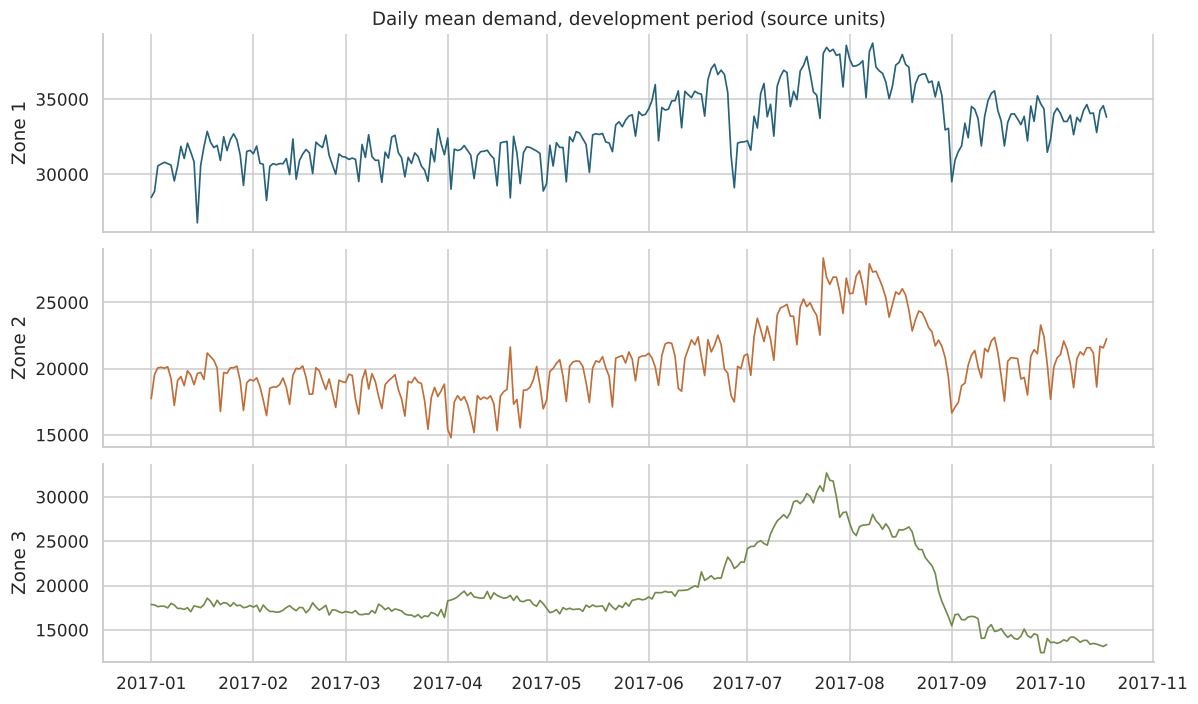

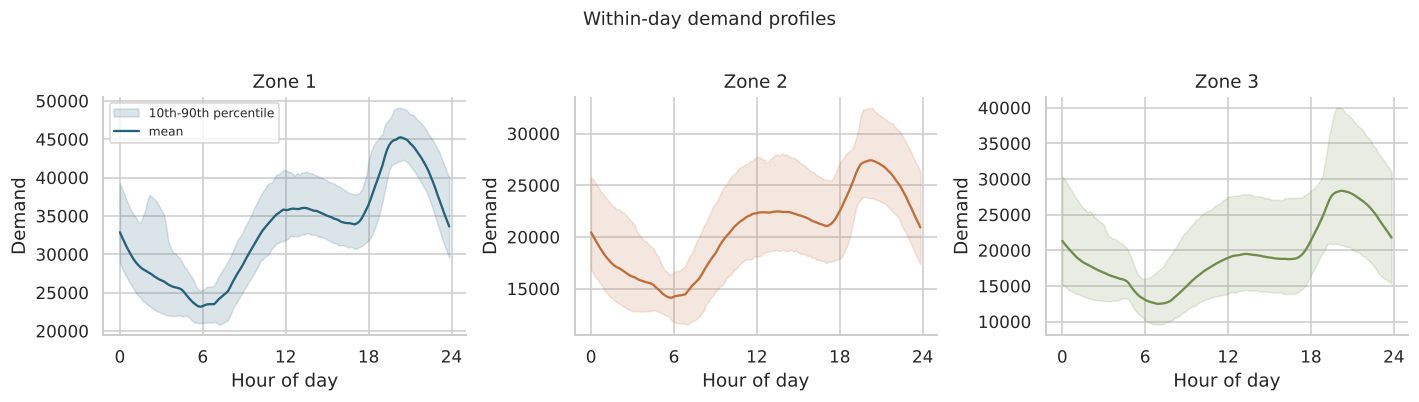

In [6]:
daily = development[TARGETS].resample("D").mean()
fig, axes = plt.subplots(3, 1, figsize=(11, 6.5), sharex=True)
for ax, zone, color in zip(axes, TARGETS, COLORS):
    ax.plot(daily.index, daily[zone], color=color, lw=1.1)
    ax.set_ylabel(LABELS[zone])
axes[0].set_title("Daily mean demand, development period (source units)")
plt.tight_layout(); plt.show()

profiles = development[TARGETS].assign(hour=development.index.hour + development.index.minute / 60)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True)
for ax, zone, color in zip(axes, TARGETS, COLORS):
    grouped = profiles.groupby("hour")[zone]
    ax.fill_between(grouped.mean().index, grouped.quantile(.1), grouped.quantile(.9), color=color, alpha=.16,
                    label="10th-90th percentile")
    ax.plot(grouped.mean().index, grouped.mean(), color=color, label="mean")
    ax.set(title=LABELS[zone], xlabel="Hour of day", ylabel="Demand", xticks=[0, 6, 12, 18, 24])
axes[0].legend(fontsize=8)
fig.suptitle("Within-day demand profiles", y=1.03); plt.tight_layout(); plt.show()

**Daily trend and daily profile.** Zones 1 and 2 rise moderately in
summer. Zone 3 behaves differently: demand surges in July–August (its
monthly mean rises by about 60 %) and then falls back below its winter level
in September–October. All three zones share the same daily shape: low
demand in the early morning, a rise through the day, and a peak around
**20:00**. The shaded band shows that the shape is stable from day to day.

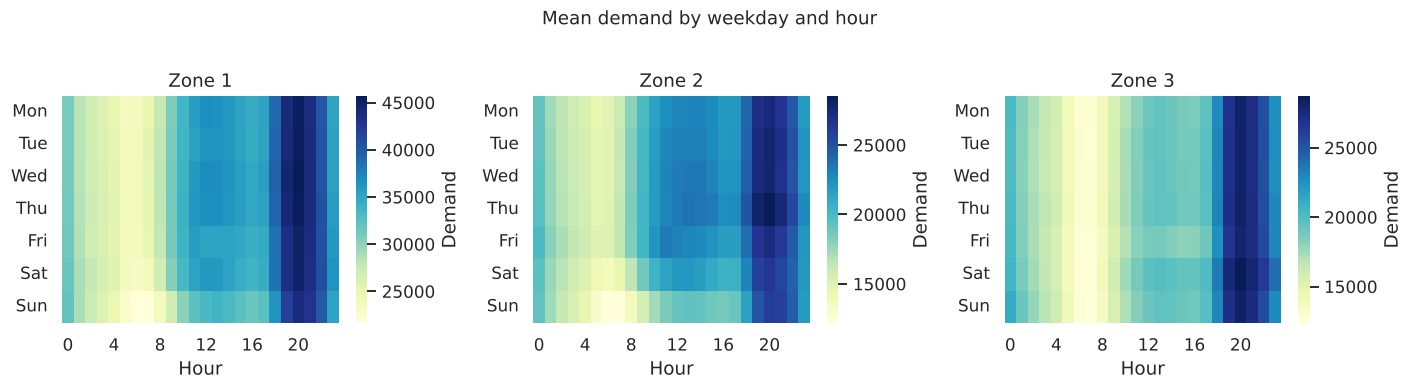

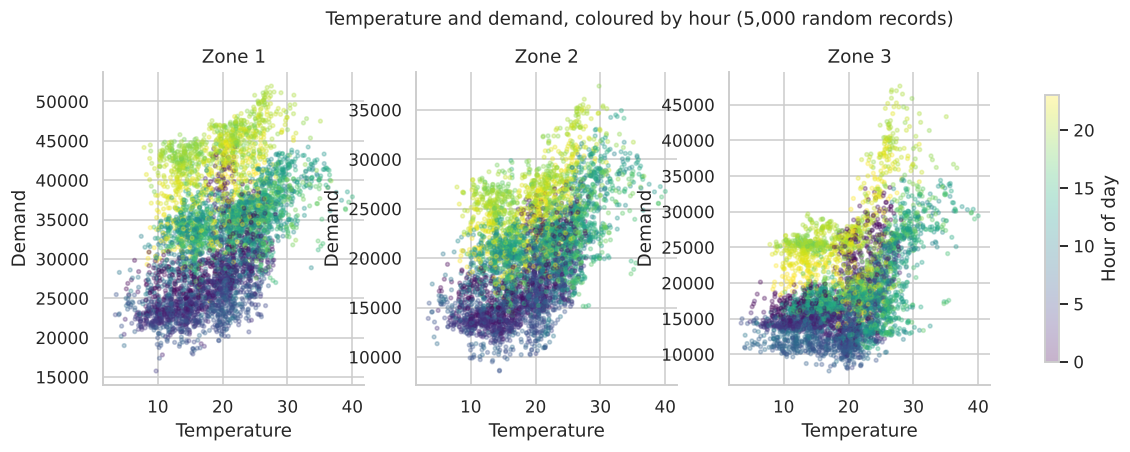

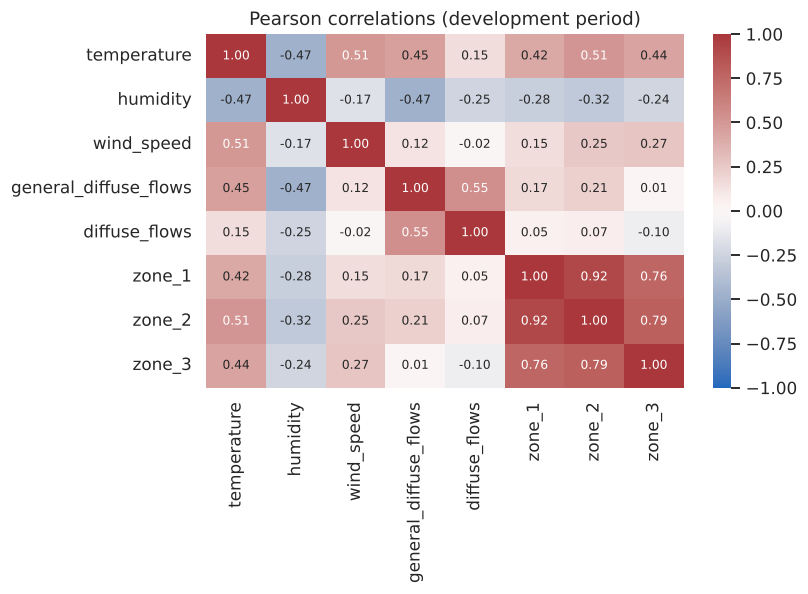

In [7]:
work = development[TARGETS].assign(weekday=development.index.dayofweek, hour=development.index.hour)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, zone in zip(axes, TARGETS):
    table = work.groupby(["weekday", "hour"])[zone].mean().unstack()
    sns.heatmap(table, ax=ax, cmap="YlGnBu", yticklabels=["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
                xticklabels=4, cbar_kws={"label": "Demand"})
    ax.tick_params(axis="y", labelrotation=0)
    ax.set(title=LABELS[zone], xlabel="Hour", ylabel="")
fig.suptitle("Mean demand by weekday and hour", y=1.03); plt.tight_layout(); plt.show()

sample = development.sample(n=5000, random_state=SEED)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, zone in zip(axes, TARGETS):
    points = ax.scatter(sample.temperature, sample[zone], c=sample.index.hour, cmap="viridis",
                        vmin=0, vmax=23, alpha=.3, s=6, rasterized=True)
    ax.set(title=LABELS[zone], xlabel="Temperature", ylabel="Demand")
fig.colorbar(points, ax=axes, label="Hour of day", shrink=.85)
fig.suptitle("Temperature and demand, coloured by hour (5,000 random records)", y=1.03); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(development[WEATHER + TARGETS].corr(), vmin=-1, vmax=1, center=0, cmap="vlag",
            annot=True, fmt=".2f", ax=ax, annot_kws={"size": 8})
ax.set_title("Pearson correlations (development period)"); plt.tight_layout(); plt.show()

**Weekdays, weather and zone differences.** In Zones 1 and 2, daytime
demand (8:00–18:59) is about 6 % and 12 % lower at weekends than on
weekdays, so the weekday is a useful input; Zone 3 shows almost no
weekend effect. Temperature is positively correlated with all three targets
(about 0.42 / 0.52 / 0.44), but the scatter plots show that hot hours are
also afternoon and evening hours: temperature and time of day move
together, so a model must separate the two. Zones 1 and 2 are strongly
correlated with each other (0.92), while Zone 3 has its own seasonal
pattern. Wind speed and humidity show only weak associations.

**Implications for modelling.** We need (i) cyclic time-of-day
features, (ii) weekday indicators, (iii) a smooth seasonal term, and
(iv) the weather variables, possibly with interactions such as
temperature × hour.

### 2.4 Experimental Protocol
* **Time split.** Model choices use the development period
  (**1 Jan – 18 Oct**, 291 days). The **final holdout** (**19 Oct – 30 Dec**,
  73 days) is used once, at the end, to report test scores.
* **Expanding-window cross-validation.** Five folds; each trains on all
  days up to a cut-off and validates on the following 28 days (June to mid-October).
  Training data always come before validation data, so no future information leaks into the past.
* **Preprocessing inside the fold.** Any learned preprocessing (for
  example the standard scaler for Ridge) is fitted on the training part
  of each fold only.
* **Metrics.** RMSE (penalises large errors), MAE (average absolute
  error), both in source units, and R² (share of variance explained,
  relative to the mean of the evaluated period). Residual = observed − predicted.
* **Selection rule.** For each model and zone, the setting with the lowest
  mean validation RMSE over the five folds.

In [8]:
splits, fold_table = cv_splits(development)
print(f"Development: {len(development):,} rows | Test: {len(holdout):,} rows")
display(fold_table)

Development: 41,904 rows | Test: 10,512 rows


,fold,train_start,train_end,train_days,validation_start,validation_end
0,1,2017-01-01,2017-05-31 23:50:00,151,2017-06-01,2017-06-28 23:50:00
1,2,2017-01-01,2017-06-28 23:50:00,179,2017-06-29,2017-07-26 23:50:00
2,3,2017-01-01,2017-07-26 23:50:00,207,2017-07-27,2017-08-23 23:50:00
3,4,2017-01-01,2017-08-23 23:50:00,235,2017-08-24,2017-09-20 23:50:00
4,5,2017-01-01,2017-09-20 23:50:00,263,2017-09-21,2017-10-18 23:50:00


## 3. Task 1: Supervised Demand Prediction
**Can we accurately estimate the demand of each zone at each ten-minute
time point from weather and calendar information?**

* Which time and weather features help prediction most?
* Are the three zones equally hard to predict?
* Is a linear relationship enough, or are there clear nonlinearities and feature interactions?
* At which times, weather conditions or zones do large errors occur?

Inputs: temperature, humidity, wind speed, the two radiation measures and
calendar features. Outputs: the demand of Zone 1, 2 and 3 (one model per
zone). This is *contemporaneous estimation*: the weather at the same time
point is assumed known; it is not a forecast of future weather.

### 3.1 Methodology: Linear regression models + EDA
**Feature engineering.** We compare three sets of inputs to see what
weather and interactions add once calendar information is present.

| Feature set | Inputs | Columns |
|---|---|---:|
| R1 | three daily sine/cosine pairs, six weekday indicators, annual sine/cosine | 14 |
| R2 | R1 + the five weather variables | 19 |
| R3 | R2 + temperature², temperature × humidity, temperature × daily sine/cosine | 23 |

Fractional hours keep the ten-minute resolution, and the sine/cosine
pairs put 23:50 next to 00:00. Monday is the weekday reference.

**Ridge regression.** One model per zone and feature set, minimising
$$\sum_{i\in\text{train}} (y_i-b-\phi(x_i)^\top w)^2+\alpha\lVert w\rVert_2^2 .$$
Continuous features are standardised (scaler fitted in each training
fold); weekday indicators stay 0/1. The penalty $\alpha$ is chosen from
$10^{-4},10^{-3},\dots,10^{6}$ by cross-validation. The baseline **B0**
predicts the training-period mean demand.

In [9]:
display(make_features(development, "R3").head(3))

ALPHAS = np.logspace(-4, 6, 11)

def ridge_pipeline(columns, alpha=1.0):
    weekdays = [c for c in columns if c.startswith("weekday_")]
    continuous = [c for c in columns if c not in weekdays]
    preprocess = ColumnTransformer([("continuous", StandardScaler(), continuous),
                                    ("weekday", "passthrough", weekdays)], verbose_feature_names_out=False)
    return Pipeline([("preprocess", preprocess), ("ridge", Ridge(alpha=alpha, solver="cholesky"))])

,daily_sin_1,daily_cos_1,daily_sin_2,daily_cos_2,daily_sin_3,daily_cos_3,weekday_1,weekday_2,weekday_3,weekday_4,...,annual_cos,temperature,humidity,wind_speed,general_diffuse_flows,diffuse_flows,temperature_squared,temperature_x_humidity,temperature_x_daily_sin,temperature_x_daily_cos
timestamp,,,,,,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,0.000,1.000,0.000,1.000,0.000,1.000,0.0,0.0,0.0,0.0,...,1.0,6.559,73.8,0.083,0.051,0.119,43.020,484.054,0.00,6.559
2017-01-01 00:10:00,0.044,0.999,0.087,0.996,0.131,0.991,0.0,0.0,0.0,0.0,...,1.0,6.414,74.5,0.083,0.070,0.085,41.139,477.843,0.28,6.408
2017-01-01 00:20:00,0.087,0.996,0.174,0.985,0.259,0.966,0.0,0.0,0.0,0.0,...,1.0,6.313,74.5,0.080,0.062,0.100,39.854,470.318,0.55,6.289


**Cross-validation of Ridge.** Ridge is fast, so its full alpha search
always runs (a few seconds). We keep the validation-fold
("out-of-fold", OOF) predictions of the selected settings for the error
analysis and for the cross-task analysis in Section 6.

In [10]:
ridge_cv_rows, ridge_alpha, oof_frames = [], {}, []
for feature_set in ["R1", "R2", "R3"]:
    x = make_features(development, feature_set)
    for zone in TARGETS:
        grid = GridSearchCV(ridge_pipeline(x.columns), {"ridge__alpha": ALPHAS}, cv=splits,
                            scoring="neg_root_mean_squared_error").fit(x, development[zone])
        alpha = float(grid.best_params_["ridge__alpha"])
        ridge_alpha[(feature_set, zone)] = alpha
        for fold, (tr, va) in enumerate(splits, 1):
            pred = ridge_pipeline(x.columns, alpha).fit(x.iloc[tr], development[zone].iloc[tr]).predict(x.iloc[va])
            ridge_cv_rows.append(dict(model=feature_set, zone=zone, alpha=alpha, fold=fold,
                                      **metric_values(development[zone].iloc[va], pred)))
            oof_frames.append(prediction_frame(x.index[va], development[zone].iloc[va], pred, zone,
                                               feature_set, json.dumps({"alpha": alpha}), "oof", fold))
for zone in TARGETS:                              # B0: training-mean baseline
    for fold, (tr, va) in enumerate(splits, 1):
        pred = np.full(len(va), development[zone].iloc[tr].mean())
        ridge_cv_rows.append(dict(model="B0", zone=zone, alpha=np.nan, fold=fold,
                                  **metric_values(development[zone].iloc[va], pred)))
        oof_frames.append(prediction_frame(development.index[va], development[zone].iloc[va], pred,
                                           zone, "B0", "", "oof", fold))

ridge_cv = pd.DataFrame(ridge_cv_rows).groupby(["model", "zone"]).agg(
    alpha=("alpha", "first"), rmse=("rmse", "mean"), mae=("mae", "mean"), r2=("r2", "mean")).reset_index()
display(ridge_cv.pivot(index="model", columns="zone", values="rmse").round(0))
display(ridge_cv.groupby("model").rmse.mean().rename("mean CV RMSE over zones").round(0))
display(ridge_cv.query("model != 'B0'").pivot(index="model", columns="zone", values="alpha"))

zone,zone_1,zone_2,zone_3
model,,,
B0,7507.0,5561.0,8071.0
R1,3525.0,3520.0,6877.0
R2,3509.0,3460.0,6636.0
R3,3579.0,3379.0,5878.0


model
B0    7046.0
R1    4641.0
R2    4535.0
R3    4278.0
Name: mean CV RMSE over zones, dtype: float64

zone,zone_1,zone_2,zone_3
model,,,
R1,1000.0,1.000e+03,1.000e+03
R2,1000.0,1.000e+03,1.000e+04
R3,10000.0,1.000e-04,1.000e-04


Mean validation RMSE falls from **4,641 (R1)** to **4,535 (R2)** and
**4,278 (R3)**, so weather helps a little and the interaction terms help
more, mostly in Zone 3. We therefore take **R3** as the primary Ridge
model; it is also the common input for the nonlinear models below. The
selected R3 alphas are 10,000 / 0.0001 / 0.0001 for Zones 1 / 2 / 3; in
Zones 2 and 3 almost no shrinkage is needed. Note how poor Ridge is in
Zone 3 (validation R² well below zero): its summer surge and drop are
not a smooth function of the inputs.

### 3.2 Methodology:  Nonlinear regression models
Ridge can only add up its inputs with one fixed weight each. Demand may
instead depend on the inputs through thresholds and interactions ("hot
*and* evening"). We therefore fit two tree ensembles on the **same R3
inputs, folds and metrics**, so that the scores compare directly with Ridge.

**Random Forest (RF).** The average of 200 regression trees, each grown
on a bootstrap sample of the rows and allowed to look at only a random
fraction (`max_features`) of the columns at each split. Averaging many
decorrelated trees reduces variance. A leaf predicts the mean demand of
its training rows, so the forest can represent thresholds and
interactions without anyone writing them down. Trees do not need scaled inputs.

**Gradient Boosting (GB).** Trees are added one at a time; each new
small tree is fitted to the residuals of the current ensemble and added
with a learning rate $\eta$:
$F_m(x)=F_{m-1}(x)+\eta\,h_m(x)$. We use scikit-learn's
`HistGradientBoostingRegressor`, which bins the inputs and is fast.

**Ridge + boosted residuals (HYB).** R3 Ridge (with its selected alpha)
fits the smooth linear part, and gradient boosting models what Ridge
leaves over: an attempt to keep Ridge's trend while adding nonlinear corrections.

*Kernel Ridge Regression was not used: exact KRR needs a
38,000 × 38,000 kernel matrix per fold (about 11 GB of memory).*

**Hyperparameter search.** For each model and zone we evaluated every
setting in the grids below on the five folds and kept the lowest mean
validation RMSE (36 settings × 3 zones × 5 folds; about 30 minutes on a
4-core laptop). The selected settings are stored in `SELECTED_PARAMS`, so with
`TRAIN_MODEL = False` the notebook only fits those (a few minutes).

In [11]:
RF_GRID = [dict(max_depth=d, min_samples_leaf=leaf, max_features=f)
           for d in (12, None) for leaf in (1, 5, 20) for f in (0.33, 0.66)]
GB_GRID = [dict(learning_rate=lr, max_iter=it, max_leaf_nodes=nodes, min_samples_leaf=leaf)
           for lr in (0.05, 0.1) for it in (200, 500) for nodes in (15, 63) for leaf in (20, 200)]
HYB_GRID = [dict(learning_rate=0.05, max_iter=it, max_leaf_nodes=nodes, min_samples_leaf=leaf)
            for it in (200, 500) for nodes in (15, 63) for leaf in (20, 200)]
GRIDS = {"RF": RF_GRID, "GB": GB_GRID, "HYB": HYB_GRID}

# Result of the full search (TRAIN_MODEL = True reproduces it).
SELECTED_PARAMS = {
    "RF": {
        "zone_1": {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1},
        "zone_2": {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1},
        "zone_3": {'max_depth': None, 'max_features': 0.33, 'min_samples_leaf': 1},
    },
    "GB": {
        "zone_1": {'learning_rate': 0.1, 'max_iter': 500, 'max_leaf_nodes': 15, 'min_samples_leaf': 200},
        "zone_2": {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 15, 'min_samples_leaf': 200},
        "zone_3": {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 15, 'min_samples_leaf': 20},
    },
    "HYB": {
        "zone_1": {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 63, 'min_samples_leaf': 200},
        "zone_2": {'learning_rate': 0.05, 'max_iter': 500, 'max_leaf_nodes': 63, 'min_samples_leaf': 200},
        "zone_3": {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 20},
    },
}


class RidgeResidualBoost(BaseEstimator, RegressorMixin):
    """Ridge for the smooth linear part + gradient boosting on the Ridge residuals."""
    def __init__(self, alpha=1.0, learning_rate=0.05, max_iter=200, max_leaf_nodes=31, min_samples_leaf=20):
        self.alpha, self.learning_rate, self.max_iter = alpha, learning_rate, max_iter
        self.max_leaf_nodes, self.min_samples_leaf = max_leaf_nodes, min_samples_leaf

    def fit(self, x, y):
        self.ridge_ = ridge_pipeline(x.columns, self.alpha).fit(x, y)
        self.boost_ = make_model("GB", dict(learning_rate=self.learning_rate, max_iter=self.max_iter,
                                            max_leaf_nodes=self.max_leaf_nodes,
                                            min_samples_leaf=self.min_samples_leaf))
        self.boost_.fit(x, np.asarray(y) - self.ridge_.predict(x))
        return self

    def predict(self, x):
        return self.ridge_.predict(x) + self.boost_.predict(x)


def make_model(model, params, zone=None):
    if model == "RF":
        return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=SEED, **params)
    if model == "GB":
        return HistGradientBoostingRegressor(l2_regularization=1.0, early_stopping=False,
                                             random_state=SEED, **params)
    if model == "HYB":
        return RidgeResidualBoost(alpha=ridge_alpha[("R3", zone)], **params)
    raise ValueError(model)

In [12]:
x_dev = make_features(development, "R3")
if TRAIN_MODEL:   # full grid search (~30 min)
    for model, grid in GRIDS.items():
        for zone in TARGETS:
            scores = []
            for params in grid:
                fold_rmse = [metric_values(development[zone].iloc[va], make_model(model, params, zone)
                                           .fit(x_dev.iloc[tr], development[zone].iloc[tr])
                                           .predict(x_dev.iloc[va]))["rmse"] for tr, va in splits]
                scores.append(np.mean(fold_rmse))
            SELECTED_PARAMS[model][zone] = grid[int(np.argmin(scores))]
            print(f"{model} / {zone}: {SELECTED_PARAMS[model][zone]}  CV RMSE {min(scores):,.0f}")

# Cross-validate the selected settings and keep their out-of-fold predictions.
nonlinear_cv_rows = []
for model in ["RF", "GB", "HYB"]:
    for zone in TARGETS:
        params = SELECTED_PARAMS[model][zone]
        for fold, (tr, va) in enumerate(splits, 1):
            pred = make_model(model, params, zone).fit(x_dev.iloc[tr], development[zone].iloc[tr]).predict(x_dev.iloc[va])
            nonlinear_cv_rows.append(dict(model=model, zone=zone, fold=fold,
                                          **metric_values(development[zone].iloc[va], pred)))
            oof_frames.append(prediction_frame(x_dev.index[va], development[zone].iloc[va], pred, zone,
                                               model, json.dumps(params), "oof", fold))
nonlinear_cv = pd.DataFrame(nonlinear_cv_rows).groupby(["model", "zone"])[["rmse", "mae", "r2"]].mean().reset_index()
oof = pd.concat(oof_frames, ignore_index=True)
display(pd.DataFrame(SELECTED_PARAMS))

,RF,GB,HYB
zone_1,"{'max_depth': None, 'max_features': 0.33, 'min...","{'learning_rate': 0.1, 'max_iter': 500, 'max_l...","{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
zone_2,"{'max_depth': None, 'max_features': 0.33, 'min...","{'learning_rate': 0.05, 'max_iter': 500, 'max_...","{'learning_rate': 0.05, 'max_iter': 500, 'max_..."
zone_3,"{'max_depth': None, 'max_features': 0.33, 'min...","{'learning_rate': 0.05, 'max_iter': 500, 'max_...","{'learning_rate': 0.05, 'max_iter': 200, 'max_..."


The forest prefers **fully grown trees** (`max_depth=None`,
`min_samples_leaf=1`) with a third of the features per split, in all
zones. Boosting prefers **many (500) small trees**. Both models choose
high flexibility and control variance by averaging (RF) or by small
steps (GB), not by limiting tree size: a sign that the target has a lot
of fine-grained structure.

**Final models.** Each selected model is refitted on the whole
development period and predicts the test period once.

In [13]:
x_test = make_features(holdout, "R3")
fitted, test_rows, test_frames = {}, [], []
for zone in TARGETS:
    mean = development[zone].mean()
    test_rows.append(dict(model="B0", zone=zone, **metric_values(holdout[zone], np.full(len(holdout), mean))))
    test_frames.append(prediction_frame(holdout.index, holdout[zone], np.full(len(holdout), mean),
                                        zone, "B0", "", "holdout"))
    for feature_set in ["R1", "R2", "R3"]:
        x_a, x_b = make_features(development, feature_set), make_features(holdout, feature_set)
        alpha = ridge_alpha[(feature_set, zone)]
        est = ridge_pipeline(x_a.columns, alpha).fit(x_a, development[zone])
        fitted[(feature_set, zone)] = est
        pred = est.predict(x_b)
        test_rows.append(dict(model=feature_set, zone=zone, **metric_values(holdout[zone], pred)))
        test_frames.append(prediction_frame(holdout.index, holdout[zone], pred, zone, feature_set,
                                            json.dumps({"alpha": alpha}), "holdout"))
    for model in ["RF", "GB", "HYB"]:
        est = make_model(model, SELECTED_PARAMS[model][zone], zone).fit(x_dev, development[zone])
        fitted[(model, zone)] = est
        pred = est.predict(x_test)
        test_rows.append(dict(model=model, zone=zone, **metric_values(holdout[zone], pred)))
        test_frames.append(prediction_frame(holdout.index, holdout[zone], pred, zone, model,
                                            json.dumps(SELECTED_PARAMS[model][zone]), "holdout"))
test_metrics = pd.DataFrame(test_rows)
test_predictions = pd.concat(test_frames, ignore_index=True)
print("Fitted", len(fitted), "models.")

Fitted 18 models.


### 3.3 Results
#### CV results and final (test) results
`MODELS` lists the models compared from here on: the baseline, the
primary Ridge model (R3) and the three nonlinear models.

RMSE


CV (Jun - Oct 18)                  \
zone                                 zone_1  zone_2  zone_3   
model                                                         
Training mean                        7507.0  5561.0  8071.0   
Ridge R3                             3579.0  3379.0  5878.0   
Random Forest                        2769.0  2625.0  4311.0   
Gradient Boosting                    2831.0  2552.0  4888.0   
Ridge + boosted residuals            2725.0  2584.0  4991.0   

                          Test (Oct 19 - Dec 30)                  
zone                                      zone_1  zone_2  zone_3  
model                                                             
Training mean                             7143.0  6160.0  7900.0  
Ridge R3                                  3671.0  4546.0  3512.0  
Random Forest                             3290.0  3681.0  6002.0  
Gradient Boosting                         4008.0  3716.0  6667.0  
Ridge + boosted residuals                 3632.0  3421.0  6459.0

R²


CV (Jun - Oct 18)                \
zone                                 zone_1 zone_2 zone_3   
model                                                       
Training mean                        -0.186 -0.475 -1.559   
Ridge R3                              0.718  0.398 -0.859   
Random Forest                         0.827  0.613  0.055   
Gradient Boosting                     0.807  0.630 -0.118   
Ridge + boosted residuals             0.825  0.627 -0.152   

                          Test (Oct 19 - Dec 30)                
zone                                      zone_1 zone_2 zone_3  
model                                                           
Training mean                             -0.344 -0.261 -4.749  
Ridge R3                                   0.645  0.313 -0.136  
Random Forest                              0.715  0.550 -2.318  
Gradient Boosting                          0.577  0.541 -3.095  
Ridge + boosted residuals                  0.652  0.611 -2.843

,CV mean RMSE,Test mean RMSE
model,,
Training mean,7046.0,7067.0
Ridge R3,4278.0,3910.0
Random Forest,3235.0,4324.0
Gradient Boosting,3424.0,4797.0
Ridge + boosted residuals,3433.0,4504.0


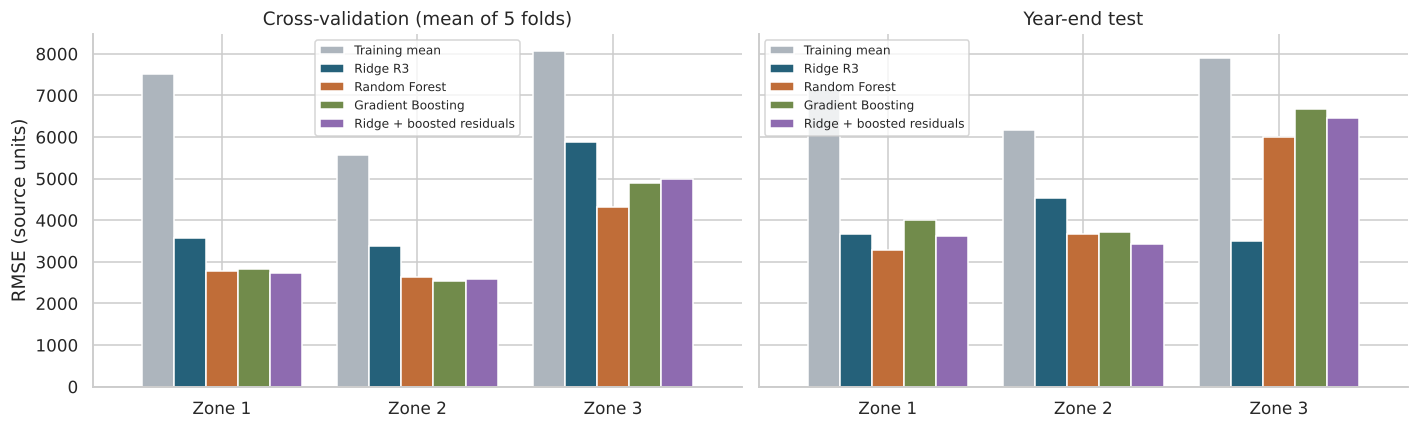

In [14]:
MODELS = ["B0", "R3", "RF", "GB", "HYB"]
NAMES = {"B0": "Training mean", "R1": "Ridge R1", "R2": "Ridge R2", "R3": "Ridge R3",
         "RF": "Random Forest", "GB": "Gradient Boosting", "HYB": "Ridge + boosted residuals"}
MODEL_COLORS = {"B0": "#adb5bd", "R3": "#25617a", "RF": "#c06d38", "GB": "#718b4b", "HYB": "#8e6bb0"}
cv_all = pd.concat([ridge_cv.drop(columns="alpha"), nonlinear_cv], ignore_index=True)

def side_by_side(metric):
    cv = cv_all.pivot(index="model", columns="zone", values=metric)
    test = test_metrics.pivot(index="model", columns="zone", values=metric)
    return pd.concat({"CV (Jun - Oct 18)": cv, "Test (Oct 19 - Dec 30)": test}, axis=1).reindex(MODELS).rename(index=NAMES)

print("RMSE"); display(side_by_side("rmse").round(0))
print("R²"); display(side_by_side("r2").round(3))
display(pd.DataFrame({"CV mean RMSE": cv_all.groupby("model").rmse.mean(),
                      "Test mean RMSE": test_metrics.groupby("model").rmse.mean()})
        .reindex(MODELS).rename(index=NAMES).round(0))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, table) in zip(axes, [("Cross-validation (mean of 5 folds)", cv_all), ("Year-end test", test_metrics)]):
    table.pivot(index="zone", columns="model", values="rmse").reindex(TARGETS)[MODELS] \
        .rename(index=LABELS, columns=NAMES).plot.bar(ax=ax, rot=0, width=.82, color=[MODEL_COLORS[m] for m in MODELS])
    ax.set(title=title, xlabel="", ylabel="RMSE (source units)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Cross-validation: the nonlinear models win clearly.** Averaged over the
three zones, validation RMSE falls from **4,278 (Ridge R3)** to
**3,235 (Random Forest)**, about **24 % lower**; boosting and the hybrid
reach roughly 3,400–3,450. RF raises the validation R² from 0.72 to 0.83 in
Zone 1 and from 0.40 to 0.61 in Zone 2, and it is the only model with a
positive validation R² in Zone 3.

**Year-end test: the picture splits by zone.**
* **Zone 1:** RF is best (RMSE 3,290 vs 3,671 for Ridge; R² 0.71 vs 0.64).
* **Zone 2:** all nonlinear models beat Ridge (RMSE about 3,400–3,700 vs 4,546 for Ridge; R² up to about 0.6 vs 0.31).
* **Zone 3:** every tree-based model fails (RMSE around 6,000–6,700, R² far below zero), while Ridge stays at 3,512.

Relative to the training-mean baseline, Ridge R3 lowers the test RMSE by
49 % / 26 % / 56 % in Zones 1 / 2 / 3. Even so, Ridge's Zone 3 R² is
−0.14: R² compares with the *test-period* mean, which already knows the
year-end level. "Nonlinear is better" holds when the test period looks
like the training period and fails when it does not; the next
subsections explain why.

#### Which features matter most?
Tree models have no coefficients, so we use **grouped permutation
importance** on the test set: shuffle one *raw* input across rows,
recompute every engineered column built from it (for example
temperature², temperature × humidity and temperature × hour all follow
temperature), and measure how much the RMSE rises. The six daily
sine/cosine columns are shuffled together as "time of day". A negative
value means the model did *better* without that input: what it learned
from it did not hold in the test period.

zone                   zone_1                          zone_2                  \
model                      GB     HYB      R3      RF      GB     HYB      R3   
group                                                                           
time of day            5599.0  5436.0  4467.0  5827.0  3699.0  4040.0  3145.0   
weekday                 147.0   155.0    41.0   115.0   238.0   262.0   159.0   
season (annual)          68.0    52.0     5.0    50.0   -11.0  -104.0   -50.0   
temperature              44.0   -23.0   138.0   275.0    -7.0  -100.0  -201.0   
humidity                -13.0    21.0    20.0    94.0   -26.0   -14.0   -26.0   
wind speed               -6.0    -5.0     5.0     6.0    17.0    -6.0   -14.0   
general diffuse flows   173.0   319.0     0.0   130.0    81.0    33.0     6.0   
diffuse flows            84.0   104.0     2.0    90.0   -25.0     4.0     5.0   

zone                           zone_3                          
model                      RF      GB     HYB      R3      RF  
group                                                          
time of day            3580.0  1476.0  1901.0  2719.0  1674.0  
weekday                 208.0     1.0     5.0     2.0     1.0  
season (annual)          28.0  -101.0   -18.0   -42.0  -113.0  
temperature             -11.0   -56.0   621.0   776.0    11.0  
humidity                -49.0   -23.0   130.0   208.0   -21.0  
wind speed                4.0    -1.0   -19.0    21.0    -0.0  
general diffuse flows    29.0   -26.0    -1.0    -2.0    35.0  
diffuse flows           -21.0   -11.0    -1.0   -23.0    42.0

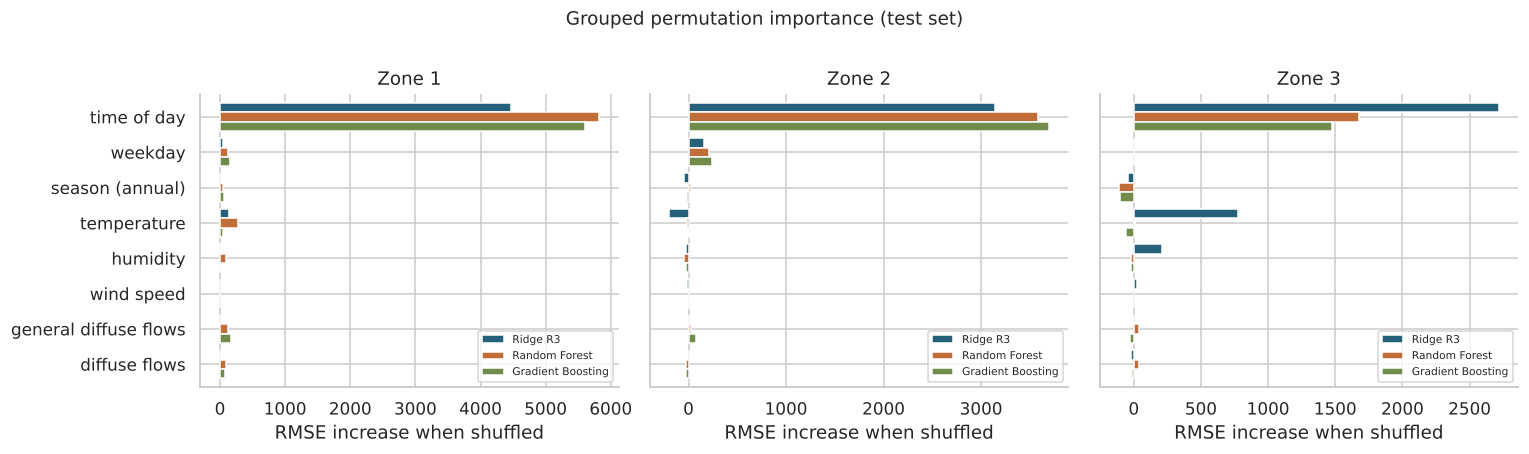

In [15]:
GROUPS = {"time of day": [f"daily_{f}_{k}" for k in (1, 2, 3) for f in ("sin", "cos")],
          "weekday": [f"weekday_{d}" for d in range(1, 7)],
          "season (annual)": ["annual_sin", "annual_cos"],
          **{w.replace("_", " "): [w] for w in WEATHER}}

def rebuild_interactions(x):
    x = x.copy()
    x["temperature_squared"] = x["temperature"] ** 2
    x["temperature_x_humidity"] = x["temperature"] * x["humidity"]
    x["temperature_x_daily_sin"] = x["temperature"] * x["daily_sin_1"]
    x["temperature_x_daily_cos"] = x["temperature"] * x["daily_cos_1"]
    return x

rng, importance_rows = np.random.default_rng(SEED), []
for zone in TARGETS:
    y = holdout[zone].to_numpy()
    for model in ["R3", "RF", "GB", "HYB"]:
        est = fitted[(model, zone)]
        base = metric_values(y, est.predict(x_test))["rmse"]
        for group, columns in GROUPS.items():
            increase = []
            for _ in range(5):
                shuffled = x_test.copy()
                shuffled[columns] = x_test[columns].to_numpy()[rng.permutation(len(x_test))]
                increase.append(metric_values(y, est.predict(rebuild_interactions(shuffled)))["rmse"] - base)
            importance_rows.append(dict(zone=zone, model=model, group=group, rmse_increase=np.mean(increase)))
importance = pd.DataFrame(importance_rows)
display(importance.pivot_table(index="group", columns=["zone", "model"], values="rmse_increase")
        .reindex(list(GROUPS)).round(0))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, zone in zip(axes, TARGETS):
    importance[importance.zone == zone].pivot(index="group", columns="model", values="rmse_increase") \
        .reindex(list(GROUPS))[["R3", "RF", "GB"]].rename(columns=NAMES) \
        .plot.barh(ax=ax, width=.8, color=[MODEL_COLORS[m] for m in ["R3", "RF", "GB"]])
    ax.set(title=LABELS[zone], xlabel="RMSE increase when shuffled", ylabel=""); ax.invert_yaxis()
    ax.legend(fontsize=7, loc="lower right")
fig.suptitle("Grouped permutation importance (test set)", y=1.02); plt.tight_layout(); plt.show()

**Time of day is by far the most useful input, then the weekday;
weather adds comparatively little.** Shuffling the time of day raises
the test RMSE by roughly **4,500–5,800** in Zone 1, **3,100–4,000** in Zone 2 and
**1,500–2,700** in Zone 3 for every model, one to two orders of magnitude
more than any weather variable. The weekday is a clear second in Zones 1
and 2 and hardly matters in Zone 3. Among weather inputs, the trees use
**temperature** and **solar radiation** in Zone 1; in Zone 3 temperature
matters to Ridge (+776) but almost not to the trees. For the forests,
**season has negative importance in Zone 3**: their test error falls when
the date is scrambled, a first hint that they learned a seasonal level
that did not repeat. Wind speed is useless everywhere.

Interpretation: demand follows people's daily routine much more than the
weather; the weather mainly shifts that routine up or down in hot periods.

#### Is linear enough? Nonlinear effects versus interactions
To separate the two possible gains cleanly, we use the raw inputs **R2**
(no hand-made interaction terms) and fit three models on the same folds:

| model | nonlinear in each input? | inputs interact? |
|---|---|---|
| Ridge R2 | no | no |
| GB with `interaction_cst="no_interactions"` | yes | no (a sum of one-variable curves) |
| GB without constraint | yes | yes |

Row 1 → 2 measures the value of nonlinear main effects; row 2 → 3 the
value of interactions (GB settings as selected for each zone).

zone,zone_1,zone_2,zone_3
model,,,
Ridge R2 (linear),3509.0,3460.0,6636.0
"GB R2, no interactions",3374.0,3016.0,5529.0
"GB R2, interactions allowed",2776.0,2577.0,4984.0


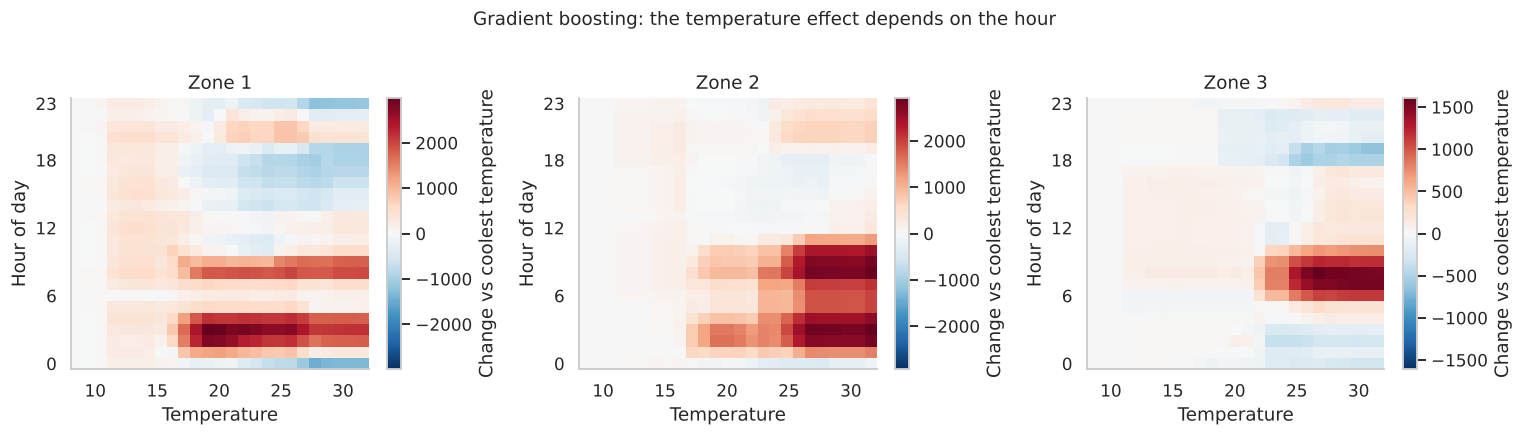

In [16]:
x_dev_r2, interaction_rows, gb_r2 = make_features(development, "R2"), [], {}
for zone in TARGETS:
    interaction_rows.append(dict(zone=zone, model="Ridge R2 (linear)",
                                 cv_rmse=ridge_cv.query("model == 'R2' and zone == @zone").rmse.iloc[0]))
    for label, extra in [("GB R2, no interactions", {"interaction_cst": "no_interactions"}),
                         ("GB R2, interactions allowed", {})]:
        proto = make_model("GB", SELECTED_PARAMS["GB"][zone]).set_params(**extra)
        rmse = [metric_values(development[zone].iloc[va], clone(proto).fit(x_dev_r2.iloc[tr], development[zone].iloc[tr])
                              .predict(x_dev_r2.iloc[va]))["rmse"] for tr, va in splits]
        interaction_rows.append(dict(zone=zone, model=label, cv_rmse=np.mean(rmse)))
        if not extra:
            gb_r2[zone] = clone(proto).fit(x_dev_r2, development[zone])
interactions = pd.DataFrame(interaction_rows).pivot(index="model", columns="zone", values="cv_rmse") \
    .loc[["Ridge R2 (linear)", "GB R2, no interactions", "GB R2, interactions allowed"]]
display(interactions.round(0))

# How does the effect of temperature depend on the hour? (GB with interactions, R2 inputs)
sample = x_dev_r2.sample(1500, random_state=SEED)
temps, hours = np.linspace(*development.temperature.quantile([.02, .98]), 25), np.arange(24.0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, zone in zip(axes, TARGETS):
    grid = np.zeros((len(hours), len(temps)))
    for i, h in enumerate(hours):
        s = sample.copy()
        for k in (1, 2, 3):
            s[f"daily_sin_{k}"], s[f"daily_cos_{k}"] = np.sin(2 * np.pi * k * h / 24), np.cos(2 * np.pi * k * h / 24)
        for j, t in enumerate(temps):
            s["temperature"] = t
            grid[i, j] = gb_r2[zone].predict(s).mean()
    change = grid - grid[:, :1]          # change relative to the coolest temperature, per hour
    limit = np.abs(change).max()
    mesh = ax.pcolormesh(temps, hours, change, cmap="RdBu_r", shading="auto", vmin=-limit, vmax=limit)
    ax.set(title=LABELS[zone], xlabel="Temperature", ylabel="Hour of day", yticks=[0, 6, 12, 18, 23])
    fig.colorbar(mesh, ax=ax, label="Change vs coolest temperature")
fig.suptitle("Gradient boosting: the temperature effect depends on the hour", y=1.03); plt.tight_layout(); plt.show()

**The relationship is clearly not linear, and interactions matter as
much as curvature.** In cross-validation, nonlinear main effects alone
cut RMSE by roughly **4 % / 13 % / 17 %** (Zones 1 / 2 / 3); allowing
interactions cuts it by a further **10–18 %** in every zone. The model finds
these interactions by itself: GB on the raw R2 inputs is as good as GB on
R3 with hand-made terms.

The heat-maps show the most important interaction. Heat raises the
predicted demand mainly **at night and in the morning, and only above a
threshold**: in Zone 2 between about 0:00 and 11:00 once temperature
passes ~25, in Zone 3 between about 6:00 and 10:00 above ~23, and in
Zone 1 around 1:00–5:00 and 8:00–9:00 above ~18 (plausibly cooling on
hot nights and mornings). In the evening the same heat has little or
even a negative effect. A linear model has one temperature slope and
cannot represent a threshold that applies only at some hours.

#### Error analysis: which zone is hardest, and where do large errors occur?
Since each error is $y-\hat y$, the squared RMSE splits exactly into a
constant **level offset** (bias = mean residual) and the **spread**
around it: $\mathrm{RMSE}^2=\text{bias}^2+\text{spread}^2$. Spread
measures whether a model gets the *shape* of demand right; bias whether
it gets the overall *level* right.

bias                     spread           \
zone                        zone_1   zone_2   zone_3   zone_1   zone_2   
model                                                                    
Ridge R3                  -2729.97  3741.76 -1896.85  2454.32  2581.70   
Random Forest             -2648.10  3057.15 -5284.06  1952.42  2049.74   
Gradient Boosting         -3442.11  3124.01 -5970.45  2053.38  2012.12   
Ridge + boosted residuals -3034.43  2631.69 -5176.71  1995.67  2185.65   

                                   bias_share_of_MSE                
zone                        zone_3            zone_1 zone_2 zone_3  
model                                                               
Ridge R3                   2955.45              0.55   0.68   0.29  
Random Forest              2846.44              0.65   0.69   0.78  
Gradient Boosting          2967.03              0.74   0.71   0.80  
Ridge + boosted residuals  3862.95              0.70   0.59   0.64

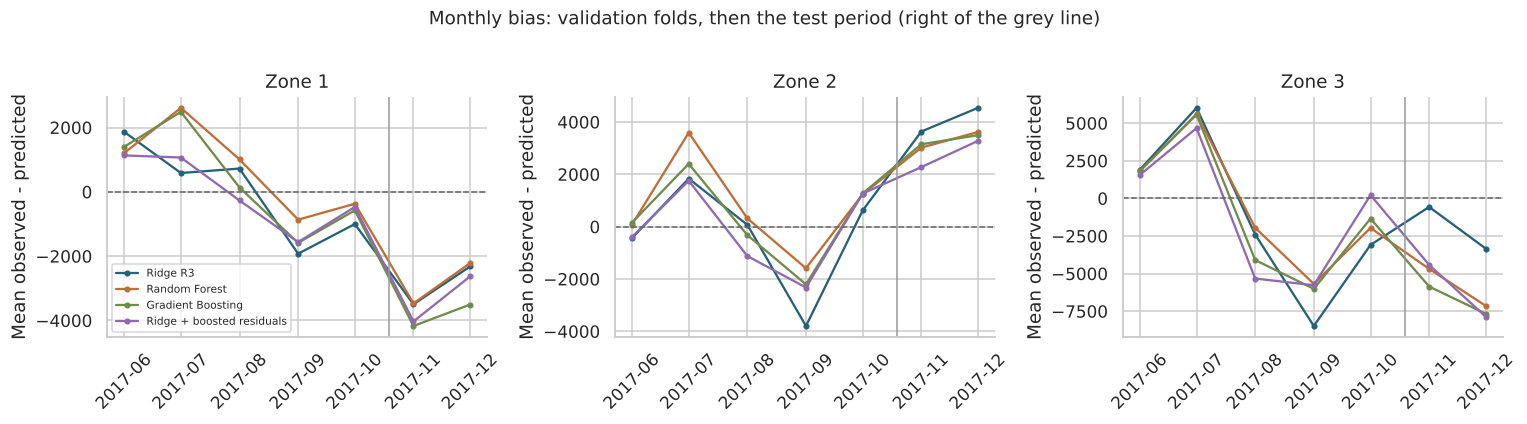

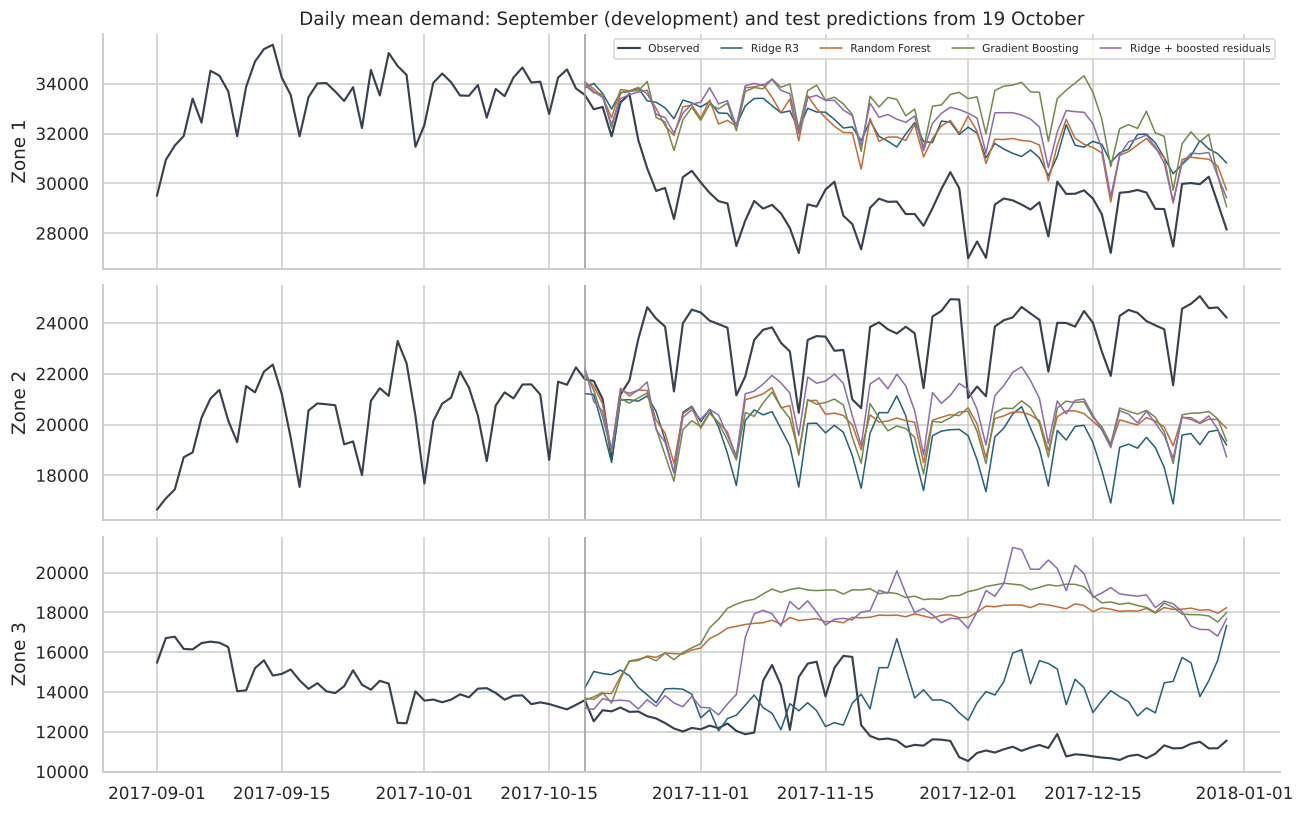

In [17]:
main = test_predictions[test_predictions.model.isin(["R3", "RF", "GB", "HYB"])].copy()
decomposition = main.groupby(["zone", "model"]).residual.agg(bias="mean", spread=lambda r: r.std(ddof=0))
decomposition["bias_share_of_MSE"] = decomposition.bias ** 2 / (decomposition.bias ** 2 + decomposition.spread ** 2)
display(decomposition.unstack("zone").reindex(["R3", "RF", "GB", "HYB"]).rename(index=NAMES).round(2))

# Monthly bias across validation folds (Jun - Oct 18) and the test period.
both = pd.concat([oof, test_predictions], ignore_index=True)
both = both[both.model.isin(["R3", "RF", "GB", "HYB"])]
both["month"] = pd.to_datetime(both.timestamp).dt.to_period("M").dt.to_timestamp()
monthly = both.groupby(["zone", "model", "month"]).residual.mean().rename("bias").reset_index()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.7))
for ax, zone in zip(axes, TARGETS):
    for model in ["R3", "RF", "GB", "HYB"]:
        z = monthly[(monthly.zone == zone) & (monthly.model == model)]
        ax.plot(z.month, z.bias, "-o", ms=3, color=MODEL_COLORS[model], label=NAMES[model])
    ax.axhline(0, color="#666666", lw=1, ls="--"); ax.axvline(pd.Timestamp(TEST_START), color="#999999", lw=1)
    ax.set(title=LABELS[zone], ylabel="Mean observed - predicted"); ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(fontsize=7)
fig.suptitle("Monthly bias: validation folds, then the test period (right of the grey line)", y=1.03)
plt.tight_layout(); plt.show()

# Daily means: observed vs predicted around the start of the test period.
main["day"] = pd.to_datetime(main.timestamp).dt.normalize()
daily_pred = main.groupby(["zone", "model", "day"]).y_pred.mean()
fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True)
for ax, zone in zip(axes, TARGETS):
    observed = data.loc["2017-09-01":, zone].resample("D").mean()
    ax.plot(observed.index, observed, color="#374151", lw=1.4, label="Observed")
    for model in ["R3", "RF", "GB", "HYB"]:
        ax.plot(daily_pred.loc[(zone, model)], color=MODEL_COLORS[model], lw=1, label=NAMES[model])
    ax.axvline(pd.Timestamp(TEST_START), color="#999999", lw=1); ax.set_ylabel(LABELS[zone])
axes[0].legend(ncol=5, fontsize=7)
axes[0].set_title("Daily mean demand: September (development) and test predictions from 19 October")
plt.tight_layout(); plt.show()

**Most of the test error is a level shift, not a shape error.** For the
nonlinear models **roughly 60–80 % of the test MSE is bias**. Without the
offset, the trees reproduce the within-day shape better than Ridge in
Zones 1 and 2 (spread about 2,000 vs about 2,450–2,580 for Ridge). All models
over-predict Zones 1 and 3 and under-predict Zone 2: year-end demand sat
at a level the calendar and weather inputs had not shown before.

The monthly plot shows that level errors exist already in the
validation months: Zone 3's bias swings from about +6,000 in July to
−6,000 in September for every model, because its summer surge is only
partly explained by the inputs. The daily-mean plot shows what goes
wrong in Zone 3 at the end of the year. Observed demand falls to about
**11,000**, lower than in any training month. The trees see cool weather
near the turn of the year, the most similar training rows are from
January–April (17,000–18,000), and that is what they predict. **A tree
cannot predict below the lowest level it saw in training; it can only
reuse levels it has already seen.** Ridge's smooth annual sine/cosine
happens to bend down late in the year, which keeps it closer. The hybrid
does not fix this either; its boosting stage probably re-applies the
summer residual pattern. Zone 2 is the mirror image: it *rose* to about
24,000, so every model under-predicts it, though the trees less than Ridge.

In [18]:
difficulty = []
for zone in TARGETS:
    for model in ["R3", "RF", "GB", "HYB"]:
        cv = cv_all.query("model == @model and zone == @zone").iloc[0]
        te = test_metrics.query("model == @model and zone == @zone").iloc[0]
        difficulty.append(dict(zone=zone, model=model, cv_r2=cv.r2, test_r2=te.r2,
                               cv_nrmse=cv.rmse / development[zone].mean(), test_nrmse=te.rmse / holdout[zone].mean()))
display(pd.DataFrame(difficulty).pivot(index="model", columns="zone", values=["cv_r2", "test_r2", "cv_nrmse", "test_nrmse"])
        .reindex(["R3", "RF", "GB", "HYB"]).rename(index=NAMES).round(3))

cv_r2               test_r2               cv_nrmse  \
zone                      zone_1 zone_2 zone_3  zone_1 zone_2 zone_3   zone_1   
model                                                                           
Ridge R3                   0.718  0.398 -0.859   0.645  0.313 -0.136    0.108   
Random Forest              0.827  0.613  0.055   0.715  0.550 -2.318    0.084   
Gradient Boosting          0.807  0.630 -0.118   0.577  0.541 -3.095    0.086   
Ridge + boosted residuals  0.825  0.627 -0.152   0.652  0.611 -2.843    0.082   

                                        test_nrmse                
zone                      zone_2 zone_3     zone_1 zone_2 zone_3  
model                                                             
Ridge R3                   0.165  0.305      0.125  0.195  0.290  
Random Forest              0.128  0.224      0.112  0.158  0.496  
Gradient Boosting          0.125  0.254      0.136  0.160  0.551  
Ridge + boosted residuals  0.126  0.259      0.123  0.147  0.534

**The zones are not equally hard** (nRMSE = RMSE / mean demand of the zone, so zones of different size compare fairly):
* **Zone 1 is the easiest:** best CV R² ≈ 0.83, test R² ≈ 0.71, nRMSE about 8–11 %. Its demand is large, stable and follows the daily routine.
* **Zone 2 is intermediate:** CV R² ≈ 0.63, but its level drifts upward at the end of the year.
* **Zone 3 is by far the hardest:** CV R² is around zero even for the best model; its summer surge and its year-end drop are not explained by weather and calendar inputs.

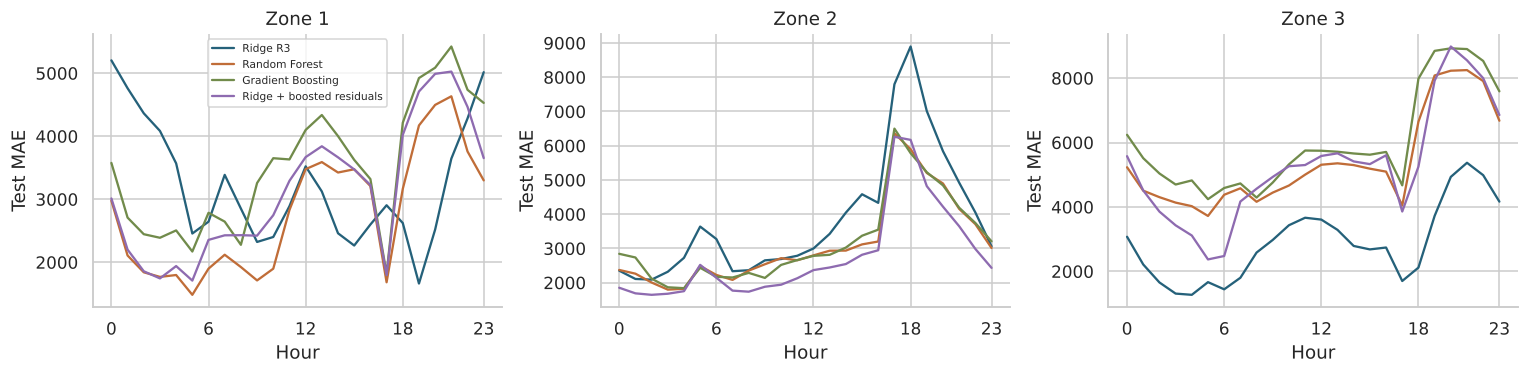

Largest 5 % of absolute test errors: share of them that are ...


over_predicted  evening_17_23h  weekend  december  \
zone   model                                                      
zone_1 GB               1.00            0.60     0.36      0.38   
       HYB              1.00            0.66     0.29      0.21   
       R3               0.93            0.41     0.29      0.18   
       RF               1.00            0.53     0.38      0.21   
zone_2 GB               0.00            0.98     0.21      0.47   
       HYB              0.00            1.00     0.21      0.53   
       R3               0.00            1.00     0.21      0.56   
       RF               0.00            0.99     0.11      0.53   
zone_3 GB               1.00            1.00     0.30      0.71   
       HYB              1.00            0.90     0.24      0.89   
       R3               0.95            0.65     0.30      0.76   
       RF               1.00            1.00     0.27      0.92   

              lower_temperature_band  
zone   model                          
zone_1 GB                       0.38  
       HYB                      0.21  
       R3                       0.19  
       RF                       0.15  
zone_2 GB                       0.47  
       HYB                      0.48  
       R3                       0.52  
       RF                       0.51  
zone_3 GB                       0.81  
       HYB                      0.94  
       R3                       0.93  
       RF                       0.93

Test MAE by temperature band (bands = development-period tertiles)


model                        GB     HYB      R3      RF
zone   temperature_band                                
zone_1 lower             3452.0  2741.0  3121.0  2197.0
       middle            3623.0  3540.0  3382.0  3427.0
       upper             1809.0  2399.0  2339.0  2535.0
zone_2 lower             3363.0  2903.0  4017.0  3439.0
       middle            3057.0  2640.0  3698.0  2865.0
       upper             2187.0  2117.0  2671.0  2110.0
zone_3 lower             7006.0  6669.0  3286.0  6373.0
       middle            4989.0  3880.0  2470.0  4401.0
       upper             3136.0  1419.0  2145.0  2564.0

In [19]:
main["hour"] = pd.to_datetime(main.timestamp).dt.hour
main["weekend"] = pd.to_datetime(main.timestamp).dt.dayofweek >= 5
low, high = development.temperature.quantile([1 / 3, 2 / 3])
main["temperature_band"] = pd.cut(holdout.temperature.reindex(pd.to_datetime(main.timestamp)).to_numpy(),
                                  [-np.inf, low, high, np.inf], labels=["lower", "middle", "upper"])
main["abs_error"] = main.residual.abs()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, zone in zip(axes, TARGETS):
    for model in ["R3", "RF", "GB", "HYB"]:
        z = main[(main.zone == zone) & (main.model == model)].groupby("hour").abs_error.mean()
        ax.plot(z.index, z, color=MODEL_COLORS[model], label=NAMES[model])
    ax.set(title=LABELS[zone], xlabel="Hour", ylabel="Test MAE", xticks=[0, 6, 12, 18, 23])
axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

top_rows = []
for (zone, model), g in main.groupby(["zone", "model"]):
    top = g[g.abs_error >= g.abs_error.quantile(.95)]
    top_rows.append(dict(zone=zone, model=model, over_predicted=(top.residual < 0).mean(),
                         evening_17_23h=top.hour.between(17, 23).mean(), weekend=top.weekend.mean(),
                         december=(pd.to_datetime(top.timestamp).dt.month == 12).mean(),
                         lower_temperature_band=(top.temperature_band == "lower").mean()))
print("Largest 5 % of absolute test errors: share of them that are ...")
display(pd.DataFrame(top_rows).set_index(["zone", "model"]).round(2))
print("Test MAE by temperature band (bands = development-period tertiles)")
display(main.pivot_table(index=["zone", "temperature_band"], columns="model", values="abs_error",
                         observed=True).round(0))

**Large errors cluster in the evening peak, in the cooler year-end weeks and in December.**
* **Hour:** in Zones 2 and 3, 98–100 % of the largest 5 % of RF and GB errors fall between 17:00 and 23:59, when demand is highest and a level shift is largest in absolute terms. Zone 1's largest errors are more spread over the day.
* **Direction:** in Zones 1 and 3 the large errors are all over-predictions; in Zone 2 all under-predictions (the level shift again).
* **Weather:** test hours in the coolest third of development temperatures give the largest Zone 3 errors (tree MAE more than twice as large as in the warmest third), because cool weather looks like January to the trees.
* **Month:** Zone 3 errors grow over the test period (RF bias about −2,400 in late October, −4,700 in November, −7,100 in December).
* **Weekday vs weekend:** errors are similar, so day type is not a main source of large errors.

#### Summary of Task 1

| Question | Answer |
|---|---|
| Which features help most? | Time of day dominates; the weekday is a clear second in Zones 1–2. Weather adds much less: temperature (mainly through hot-hour thresholds) and solar radiation. Wind speed is useless. |
| Are the zones equally hard? | No. Zone 1 is easiest (test R² 0.71), Zone 2 intermediate, Zone 3 hardest because of a seasonal swing the inputs do not explain. |
| Is linear enough? | No. Nonlinear main effects and interactions (mainly hour × temperature) each cut CV RMSE by roughly 10–18 %; RF lowers the mean CV RMSE by 24 % compared with Ridge. |
| Where are the large errors? | Evening peak hours, the cooler year-end weeks and December, above all in Zone 3, where tree models cannot extrapolate below demand levels seen in training. |

Within the period the models learned from, flexible models are clearly
better, which shows real nonlinear structure. When the test period
moves outside that range, the same flexibility becomes a weakness:
trees copy old levels, while the more rigid Ridge happens to follow the
trend. In practice one would retrain as new months arrive or add a
level/trend correction, and treat Zone 3 separately; Tasks 2 and 3 look
at its daily patterns in more detail.

#### Handoff files for Tasks 2, 3 and the integrated analysis
The cell below writes the files other sections use into `handoff/`:
* `daily_load_72d.csv`: 364 days × 72 hourly means (`zone_1_h00` … `zone_3_h23`), for PCA and clustering;
* `daily_metadata.csv`: daily mean weather, weekday and development/test membership;
* `task1_predictions_holdout.csv.gz` / `task1_predictions_oof.csv.gz`: every Task 1 model's test and validation-fold predictions (key `timestamp, zone, model`; residual = observed − predicted);
* `task1_metrics.csv`: CV and test scores of every model.

In [20]:
HANDOFF.mkdir(exist_ok=True)
hourly = data[TARGETS].resample("h").mean()
daily_load = pd.DataFrame({f"{zone}_h{h:02d}": hourly.loc[hourly.index.hour == h, zone].to_numpy()
                           for zone in TARGETS for h in range(24)},
                          index=pd.Index(hourly.index.normalize().unique(), name="date"))
assert daily_load.shape == (364, 72) and not daily_load.isna().any().any()
daily_load.to_csv(HANDOFF / "daily_load_72d.csv")

metadata = data[WEATHER].resample("D").mean()
metadata["weekday"] = metadata.index.dayofweek
metadata["split"] = np.where(metadata.index <= pd.Timestamp(DEV_END), "development", "holdout")
metadata.index.name = "date"
metadata.to_csv(HANDOFF / "daily_metadata.csv")

gz = {"method": "gzip", "mtime": 0}
test_predictions.to_csv(HANDOFF / "task1_predictions_holdout.csv.gz", index=False, compression=gz)
oof.to_csv(HANDOFF / "task1_predictions_oof.csv.gz", index=False, compression=gz)
pd.concat([cv_all.assign(split="cv_mean"), test_metrics.assign(split="holdout")]) \
    .to_csv(HANDOFF / "task1_metrics.csv", index=False)
print(sorted(p.name for p in HANDOFF.iterdir()))

['README.md', 'daily_load_72d.csv', 'daily_metadata.csv', 'task1_metrics.csv', 'task1_predictions_holdout.csv.gz', 'task1_predictions_oof.csv.gz']


## 4. Task 2: Dimensionality Reduction
每日负荷曲线的低维结构：一天中三个城区的完整用电曲线，能否由少量潜在成分概括？这些潜在成分分别代表什么用电模式？
- 72维日负荷曲线实际需要多少个维度才能表示？
- 最重要的成分代表整体用电水平、早高峰、晚高峰，还是城区差异？
- 三个城区的变化主要是同步的，还是存在不同模式？
- 线性低维结构是否足够，还是存在明显的非线性结构？
- 降维后能够保留多少原始信息？


### 4.1 Methodology: PCA and Kernel PCA
   - 日负荷矩阵构造；
   - 标准化；
   - 重构与可视化；


### 4.2 Result
   - 比较和解释。

## 5. Task 3: Load-Regime Clustering
典型用电日类型发现：每日负荷曲线能否自然形成若干种稳定、可解释的用电日类型？
- 数据中是否存在低负荷日、高负荷日、早高峰日或晚高峰日？
- 工作日和周末是否倾向于属于不同类型？
- 不同天气条件是否对应不同用电类型？
- 三个城区在不同类型中的用电模式有何差异？
- 某些日期是否介于两个类型之间？
- 聚类结果对初始化和聚类数量是否稳定？


### 5.1 Methodology: K-means


### 5.2 Methodology: GMM
    - 簇数选择；
    - 指标；

### 5.3 Results
    - 稳定性；
    - 簇解释。

## 6. Discussion
### 6.1 Integrated Analysis
    - 不同用电类型下的预测误差；
    - 哪些情境最困难；
    - 对总体模型分数的补充解释。
### 6.2 Limitations
    - 只有约一年数据；
    - 不能作因果解释；
    - 缺少区域背景信息；
    - 每日样本较少；
    - 结果不一定推广到其他城市。

## 7. Conclusion
    - 回答三个研究问题；
    - 不重复罗列全部数值；
    - 说明最可靠的发现。

## Appendix
### 8.1 Goups members Contribution Statement
   - 五名成员各自贡献声明；
   - FengZhengqi: GMM, model selection, cluster stability, comparison with K-means relationship between clusters and prediction errors.
   - GeYuzi: K-means, optimal cluster selection, visualization of typical daily consumption patterns.
   - WangKe: Data preprocessing, feature engineering, Ridge regression, performance evaluation.
   - ZengZijie: PCA, Kernel PCA, dimensionality selection, reconstruction errors, component interpretation.
   - ZhouSishuo: Random Forest, Gradient Boosting, hyperparameter tuning, feature importance, comparison with Ridge.
### 8.2 Generative-AI Disclosure
   - AI使用声明。
   - 评分：The use of Generative Artificial Intelligence must also be clearly indicated within the report. This includes a brief description of how and for what purposes you use the AI. If you declare that generative AI is not used, but we find reilable evidence on your AI usage, this will be considered plagiarism and your score for both parts of the final project will be zero.
### 8.3 Reproducibility
    - 软件库；
    - 随机种子；
    - 数据路径；
    - 从头运行说明；
    - 保存模型说明。